In [4]:
import numpy as np

def smooth_traces(trace_list, window=25):
    """
    Smooth each trace by averaging over a sliding window, then trim the first
    and last `window` entries (edge effects).

    Parameters
    ----------
    trace_list : list of array-like
        Each element is a 1D array of performance (e.g. all_correct_arr).
    window : int
        Number of trials over which to average; also number of points trimmed
        from each end (default 25).

    Returns
    -------
    list of np.ndarray
        Smoothed traces with first and last `window` entries removed. Length of
        each trace is len(original) - 2*window (or full length if too short).
    """
    if window < 2:
        return [np.asarray(arr).copy() for arr in trace_list]
    kernel = np.ones(window) / window
    out = []
    for arr in trace_list:
        arr = np.asarray(arr)
        smoothed = np.convolve(arr, kernel, mode='same')
        if len(arr) <= 2 * window:
            out.append(smoothed)
        else:
            out.append(smoothed[window:-window])
    return out

# Example: smoothed = smooth_traces(all_correct_arr, window=25)
# Then plot smoothed instead of all_correct_arr (x-axis: np.arange(len(smoothed[0])) or offset by window)

# Cosyne figure making

In [5]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
# from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

In [6]:
trained_paths = [
    r'K:\data\CW69\python\2025_12_19',
        r'L:\data\CW68\python\2025_12_10',
        r'L:\data\CW68\python\2025_12_12',
        r'L:\data\CW68\python\2025_12_13',
        r'L:\data\CW68\python\2025_12_15',
        r'L:\data\CW70\python\2025_11_04',
        # Add CW65 at some point
        
        r'H:\ephys_data\CW47\python\2024_10_17',
        r'H:\ephys_data\CW47\python\2024_10_22',
        r'H:\ephys_data\CW47\python\2024_10_25',
        r'K:\data\CW85\python\2026_02_07',
        r'K:\data\CW85\python\2026_02_10',
        r'K:\data\CW87\python\2026_02_20',
        r'K:\data\CW87\python\2026_02_21',
        ]

trained_paths_corr = [
    r'G:\ephys_data\CW59\python\2025_02_22',
             r'G:\ephys_data\CW59\python\2025_02_24',
             r'G:\ephys_data\CW59\python\2025_02_25',
             r'G:\ephys_data\CW59\python\2025_02_26',
             r'G:\ephys_data\CW59\python\2025_02_28',

            r'J:\ephys_data\CW49\python\2024_12_13',
                r'J:\ephys_data\CW53\python\2025_01_27',
                        r'J:\ephys_data\CW53\python\2025_01_28',
                        r'J:\ephys_data\CW53\python\2025_01_29',
                        # r'J:\ephys_data\CW53\python\2025_01_30',
                        r'J:\ephys_data\CW53\python\2025_02_01',
                        r'J:\ephys_data\CW53\python\2025_02_02',
]

naive_paths = [
        r'J:\ephys_data\CW48\python\2024_10_29',
        r'J:\ephys_data\CW48\python\2024_10_30',
        r'J:\ephys_data\CW48\python\2024_10_31',
        r'J:\ephys_data\CW48\python\2024_11_01',
        r'J:\ephys_data\CW48\python\2024_11_02',
        # r'J:\ephys_data\CW48\python\2024_11_03',
        r'J:\ephys_data\CW48\python\2024_11_04',
        r'J:\ephys_data\CW48\python\2024_11_05',
        r'J:\ephys_data\CW48\python\2024_11_06',
        ]

### Behavior plots:

Naive

In [40]:

all_correct_arr = []
for path in naive_paths:
    s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
    earlylick, correctarr, numtrials = s1.get_acc_conv(window=50)
    all_correct_arr.append(correctarr)


18 trials removed for stability reasons
only ppyr neurons: 333 --> 169
12 trials removed for stability reasons
only ppyr neurons: 385 --> 163
16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
26 trials removed for stability reasons
only ppyr neurons: 241 --> 103
47 trials removed for stability reasons
only ppyr neurons: 295 --> 84
10 trials removed for stability reasons
only ppyr neurons: 295 --> 118


In [41]:
all_correct_arr_sm = smooth_traces(all_correct_arr, window=25)


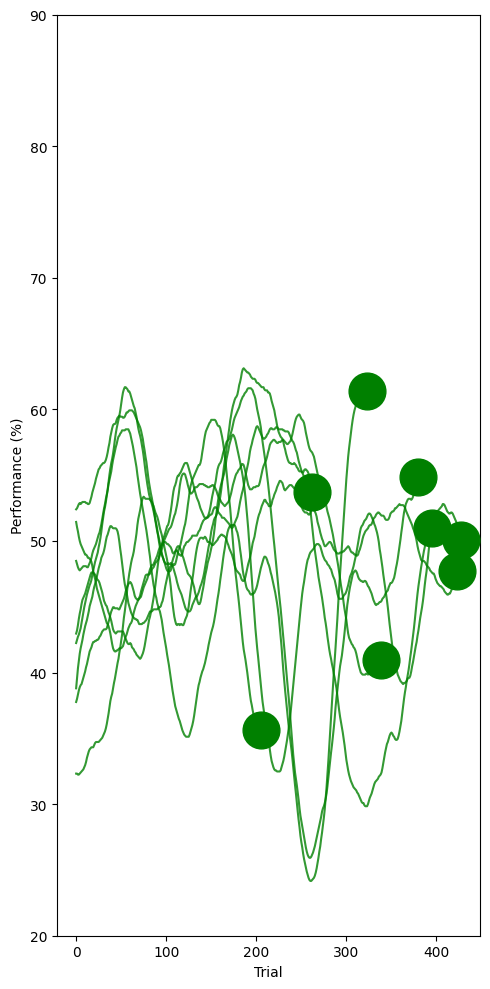

In [42]:
plt.figure(figsize=(5,10))
for arr in all_correct_arr_sm:
    x = np.arange(len(arr))
    # get_acc_conv returns fraction (0-1); convert to % for plot
    pct = arr * 100
    plt.plot(x, pct, alpha=0.8, color='green')
    # large dot at end of each trace
    plt.scatter(x[-1], pct[-1], s=700, zorder=5, color='green')
plt.xlabel('Trial')
plt.ylabel('Performance (%)')
plt.ylim(20, 90)
# label every 100 trials on x axis
max_trials = max(len(arr) for arr in all_correct_arr)
plt.xticks(np.arange(0, max_trials + 1, 100))
plt.tight_layout()
plt.savefig(r'K:\cosyne2026\behavior_naive_sm.pdf')
plt.show()


In [43]:


all_correct_arr = []
for path in trained_paths_corr:
    s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
    earlylick, correctarr, numtrials = s1.get_acc_conv(window=50)
    all_correct_arr.append(correctarr[:])


47 trials removed for stability reasons
only ppyr neurons: 359 --> 305
7 trials removed for stability reasons
only ppyr neurons: 458 --> 375
13 trials removed for stability reasons
only ppyr neurons: 193 --> 146
18 trials removed for stability reasons
only ppyr neurons: 339 --> 286
4 trials removed for stability reasons
only ppyr neurons: 222 --> 184
6 trials removed for stability reasons
only ppyr neurons: 288 --> 244
18 trials removed for stability reasons
only ppyr neurons: 295 --> 244
5 trials removed for stability reasons
only ppyr neurons: 237 --> 177
3 trials removed for stability reasons
only ppyr neurons: 388 --> 327
31 trials removed for stability reasons
only ppyr neurons: 93 --> 78
0 trials removed for stability reasons
only ppyr neurons: 296 --> 238


In [44]:
all_correct_arr_sm = smooth_traces(all_correct_arr, window=15)


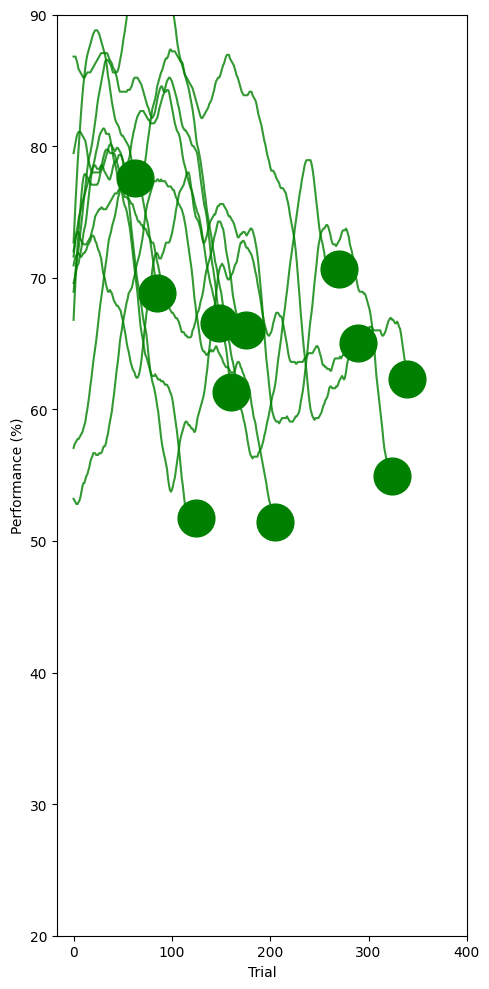

In [45]:
plt.figure(figsize=(5,10))
for arr in all_correct_arr_sm:
    x = np.arange(len(arr))
    # get_acc_conv returns fraction (0-1); convert to % for plot
    pct = arr * 100
    if pct[-1] < 60:
        x = x[:-50]
        pct = pct[:-50]
    plt.plot(x, pct, alpha=0.8, color='green')
    # large dot at end of each trace
    plt.scatter(x[-1], pct[-1], s=700, zorder=5, color='green')
plt.xlabel('Trial')
plt.ylabel('Performance (%)')
plt.ylim(20, 90)
# label every 100 trials on x axis
max_trials = max(len(arr) for arr in all_correct_arr)
plt.xticks(np.arange(0, max_trials + 1, 100))
plt.tight_layout()
plt.savefig(r'K:\cosyne2026\behavior_trained_sm.pdf')
plt.show()


## Selectivity

- as a fraction
- as a population measure

### As a fraction 

In [46]:
paths = [
        r'J:\ephys_data\CW48\python\2024_10_29',
        r'J:\ephys_data\CW48\python\2024_10_30',
        r'J:\ephys_data\CW48\python\2024_10_31',
        r'J:\ephys_data\CW48\python\2024_11_01',
        r'J:\ephys_data\CW48\python\2024_11_02',
        # r'J:\ephys_data\CW48\python\2024_11_03',
        r'J:\ephys_data\CW48\python\2024_11_04',
        r'J:\ephys_data\CW48\python\2024_11_05',
        r'J:\ephys_data\CW48\python\2024_11_06',
        ]

allsel = []
for path in paths:
    s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
    contra, ipsi = s1.plot_number_of_sig_neurons(return_nums=True, p=0.01, trialtype=True)
    allsel += [(contra + ipsi) / len(s1.good_neurons)]

18 trials removed for stability reasons
only ppyr neurons: 333 --> 169
12 trials removed for stability reasons
only ppyr neurons: 385 --> 163
16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
26 trials removed for stability reasons
only ppyr neurons: 241 --> 103
47 trials removed for stability reasons
only ppyr neurons: 295 --> 84
10 trials removed for stability reasons
only ppyr neurons: 295 --> 118


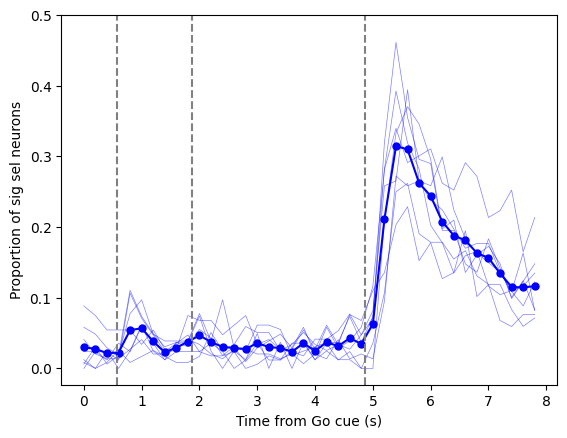

In [47]:
x = np.arange(0, 8.5, 200/1000)

plt.plot(x[:-3], np.mean(allsel, axis=0)[:-3], color = 'b', marker = 'o', markersize=5)

for i in range(len(paths)):
    plt.plot(x[:-3], allsel[i][:-3], color = 'b', alpha = 0.5, linewidth = 0.5)

plt.axvline(0.57, ls='--', color='grey')
plt.axvline(1.87, ls='--', color='grey')
plt.axvline(4.87, ls='--', color='grey')
# plt.ylim(bottom = -350)
plt.ylim(top = 0.5)
plt.ylabel('Proportion of sig sel neurons')
plt.xlabel('Time from Go cue (s)')
plt.savefig('K:\cosyne2026\proportion_naive_ephys0p1.pdf')


In [48]:

allsel = []
for path in trained_paths_corr:
    s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    contra, ipsi = s1.plot_number_of_sig_neurons(return_nums=True, p=0.01, trialtype=True)
    allsel += [(contra + ipsi) / len(s1.good_neurons)]


Remove 38 trials from session for bad behavior
47 trials removed for stability reasons
only ppyr neurons: 359 --> 306
Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 458 --> 375
Remove 0 trials from session for bad behavior
13 trials removed for stability reasons
only ppyr neurons: 193 --> 146
Remove 0 trials from session for bad behavior
18 trials removed for stability reasons
only ppyr neurons: 339 --> 286
Remove 0 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 222 --> 184
Remove 0 trials from session for bad behavior
6 trials removed for stability reasons
only ppyr neurons: 288 --> 244
Remove 24 trials from session for bad behavior
18 trials removed for stability reasons
only ppyr neurons: 295 --> 244
Remove 0 trials from session for bad behavior
5 trials removed for stability reasons
only ppyr neurons: 237 --> 177
Remove 41 trials from session for bad behavior
3 trials removed fo

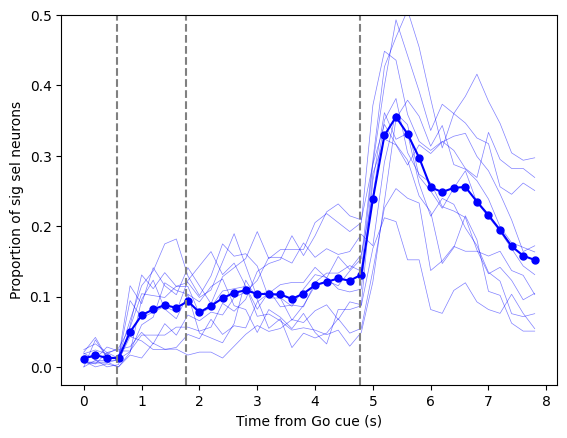

In [49]:

x = np.arange(0, 8.5, 200/1000)

plt.plot(x[:-3], np.mean(allsel, axis=0)[:-3], color = 'b', marker = 'o', markersize=5)

for i in range(len(trained_paths_corr)):
    plt.plot(x[:-3], allsel[i][:-3], color = 'b', alpha = 0.5, linewidth = 0.5)

plt.axvline(0.57, ls='--', color='grey')
plt.axvline(1.77, ls='--', color='grey')
plt.axvline(4.77, ls='--', color='grey')
# plt.ylim(bottom = -350)
plt.ylim(top = 0.5)
plt.ylabel('Proportion of sig sel neurons')
plt.xlabel('Time from Go cue (s)')
plt.savefig('K:\cosyne2026\proportion_trained_ephys0p1.pdf')

### Selectivity individual session:

In [53]:
path= r'G:\ephys_data\CW59\python\2025_02_22'

47 trials removed for stability reasons
only ppyr neurons: 359 --> 305


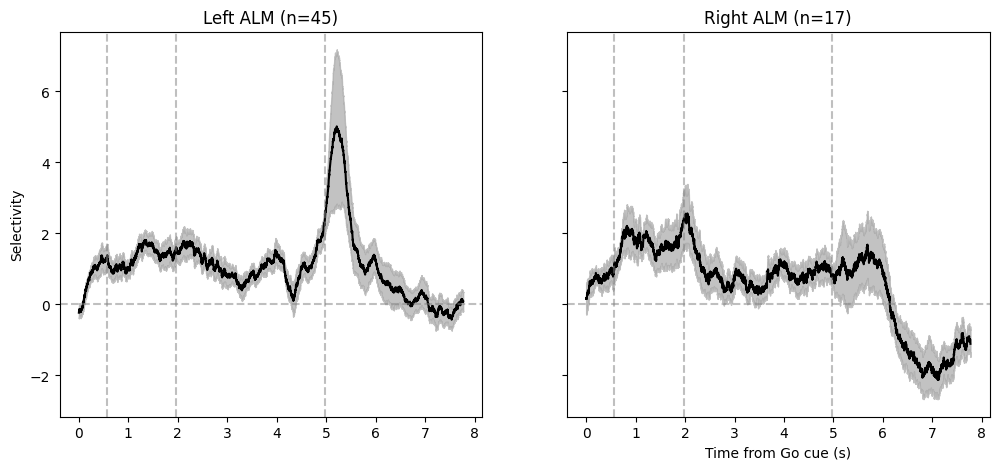

In [54]:
### Selectivity individual session:
s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                    lickdir=True,
                                                    p=0.01,
                                                    binsize=200,
                                                    timestep=100,
                                                    bootstrap=False)
plot_selectivity(s1, left_info, right_info)

### Selectivity by population

In [30]:
paths = [r'K:\data\CW69\python\2025_12_19',
        r'L:\data\CW68\python\2025_12_10',
        r'L:\data\CW68\python\2025_12_12',
        r'L:\data\CW68\python\2025_12_13',
        r'L:\data\CW68\python\2025_12_15',
        r'L:\data\CW70\python\2025_11_04',
        # Add CW65 at some point
        
        r'H:\ephys_data\CW47\python\2024_10_17',
        r'H:\ephys_data\CW47\python\2024_10_22',
        r'H:\ephys_data\CW47\python\2024_10_25',
        r'K:\data\CW85\python\2026_02_07',
        r'K:\data\CW85\python\2026_02_10',
        r'K:\data\CW87\python\2026_02_20'
        ]


In [23]:
paths = [
        r'J:\ephys_data\CW48\python\2024_10_29',
        r'J:\ephys_data\CW48\python\2024_10_30',
        r'J:\ephys_data\CW48\python\2024_10_31',
        r'J:\ephys_data\CW48\python\2024_11_01',
        r'J:\ephys_data\CW48\python\2024_11_02',
        # r'J:\ephys_data\CW48\python\2024_11_03',
        r'J:\ephys_data\CW48\python\2024_11_04',
        r'J:\ephys_data\CW48\python\2024_11_05',
        r'J:\ephys_data\CW48\python\2024_11_06',
        ]


Remove 47 trials from session for bad behavior
16 trials removed for stability reasons
only ppyr neurons: 216 --> 177
Remove 56 trials from session for bad behavior
14 trials removed for stability reasons
only ppyr neurons: 305 --> 264
Remove 0 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 422 --> 362
Remove 15 trials from session for bad behavior
5 trials removed for stability reasons
only ppyr neurons: 328 --> 280
Remove 21 trials from session for bad behavior
13 trials removed for stability reasons
only ppyr neurons: 178 --> 153
Remove 64 trials from session for bad behavior
5 trials removed for stability reasons
only ppyr neurons: 329 --> 270
Remove 151 trials from session for bad behavior
2 trials removed for stability reasons
only ppyr neurons: 271 --> 238
Remove 29 trials from session for bad behavior
3 trials removed for stability reasons
only ppyr neurons: 344 --> 288
Remove 42 trials from session for bad behavior
12 trials remo

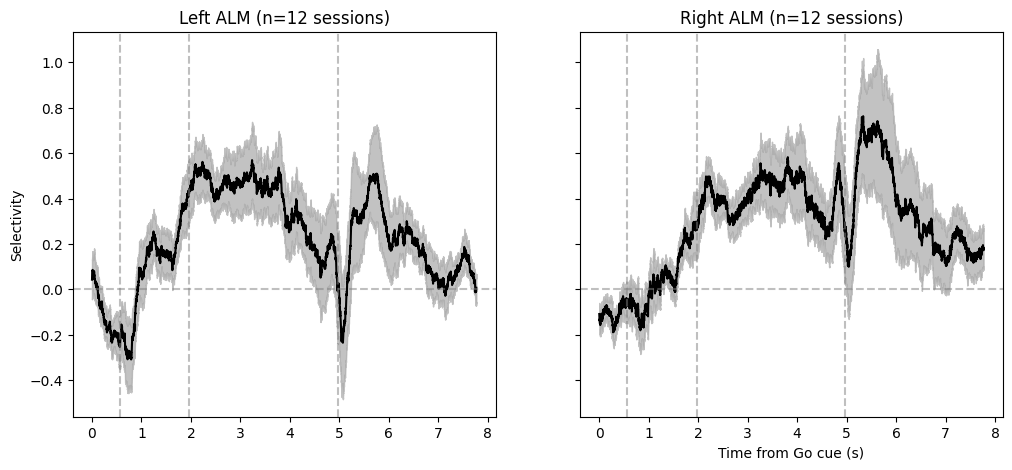

In [31]:
all_left_infos = []
all_right_infos = []
s1_ref = None
for path in paths:
    s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    epoch = (s1.delay, s1.response)
    left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                        p=0.05,
                                                        binsize=200,
                                                        timestep=100,
                                                        bootstrap=False)
                                                        
    if left_info is None:
        continue
    if s1_ref is None:
        s1_ref = s1
    all_left_infos.append(left_info)
    all_right_infos.append(right_info)

# Average selectivity across sessions and compute SEM
n_sessions = len(all_left_infos)
sel_stack = np.array([l[0] for l in all_left_infos])
selo_stimleft_stack = np.array([l[1] for l in all_left_infos])
selo_stimright_stack = np.array([l[2] for l in all_left_infos])
time = all_left_infos[0][6]
left_agg = [
    np.mean(sel_stack, axis=0),
    np.mean(selo_stimleft_stack, axis=0),
    np.mean(selo_stimright_stack, axis=0),
    np.std(sel_stack, axis=0) / np.sqrt(n_sessions),
    np.std(selo_stimleft_stack, axis=0) / np.sqrt(n_sessions),
    np.std(selo_stimright_stack, axis=0) / np.sqrt(n_sessions),
    time,
]
sel_R_stack = np.array([r[0] for r in all_right_infos])
selo_stimleft_R_stack = np.array([r[1] for r in all_right_infos])
selo_stimright_R_stack = np.array([r[2] for r in all_right_infos])
right_agg = [
    np.mean(sel_R_stack, axis=0),
    np.mean(selo_stimleft_R_stack, axis=0),
    np.mean(selo_stimright_R_stack, axis=0),
    np.std(sel_R_stack, axis=0) / np.sqrt(n_sessions),
    np.std(selo_stimleft_R_stack, axis=0) / np.sqrt(n_sessions),
    np.std(selo_stimright_R_stack, axis=0) / np.sqrt(n_sessions),
    time,
]
plot_selectivity(s1_ref, left_agg, right_agg, n_sessions=n_sessions)
plt.savefig('K:\cosyne2026\population_selectivity_trained.pdf')

## Recovery to perturbation

In [14]:
epoch

(1.9699999999999998, 4.97)

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 167


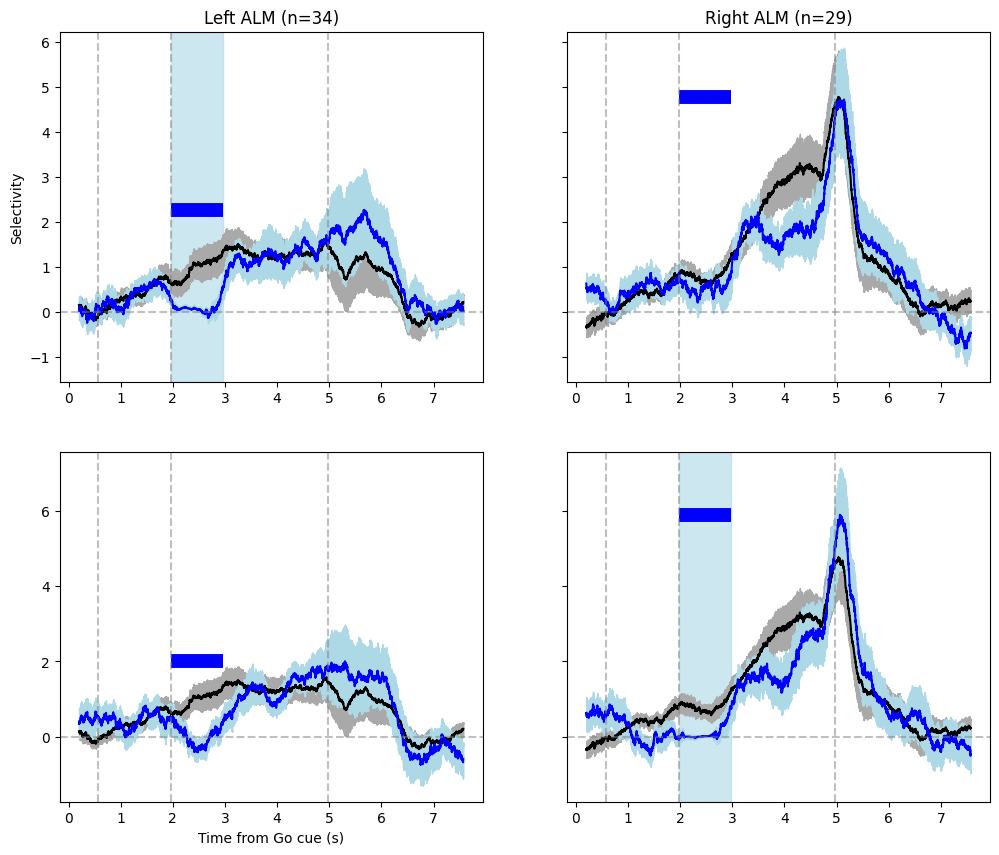

In [23]:
path = r'L:\data\CW68\python\2025_12_13'
path = r'K:\data\CW84\python\2026_03_20'

s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)


epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                    p=0.05,
                                                    binsize=400,
                                                    timestep=100,
                                                    bootstrap=False)

plot_selectivity_recovery(s1, left_info, right_info)

## Corruption data

In [8]:
reversed_mouse =   [  r'G:\ephys_data\CW59\python\2025_02_22',
             r'G:\ephys_data\CW59\python\2025_02_24',
             r'G:\ephys_data\CW59\python\2025_02_25',
             r'G:\ephys_data\CW59\python\2025_02_26',
             r'G:\ephys_data\CW59\python\2025_02_28',]
             

Remove 38 trials from session for bad behavior
47 trials removed for stability reasons
only ppyr neurons: 359 --> 306


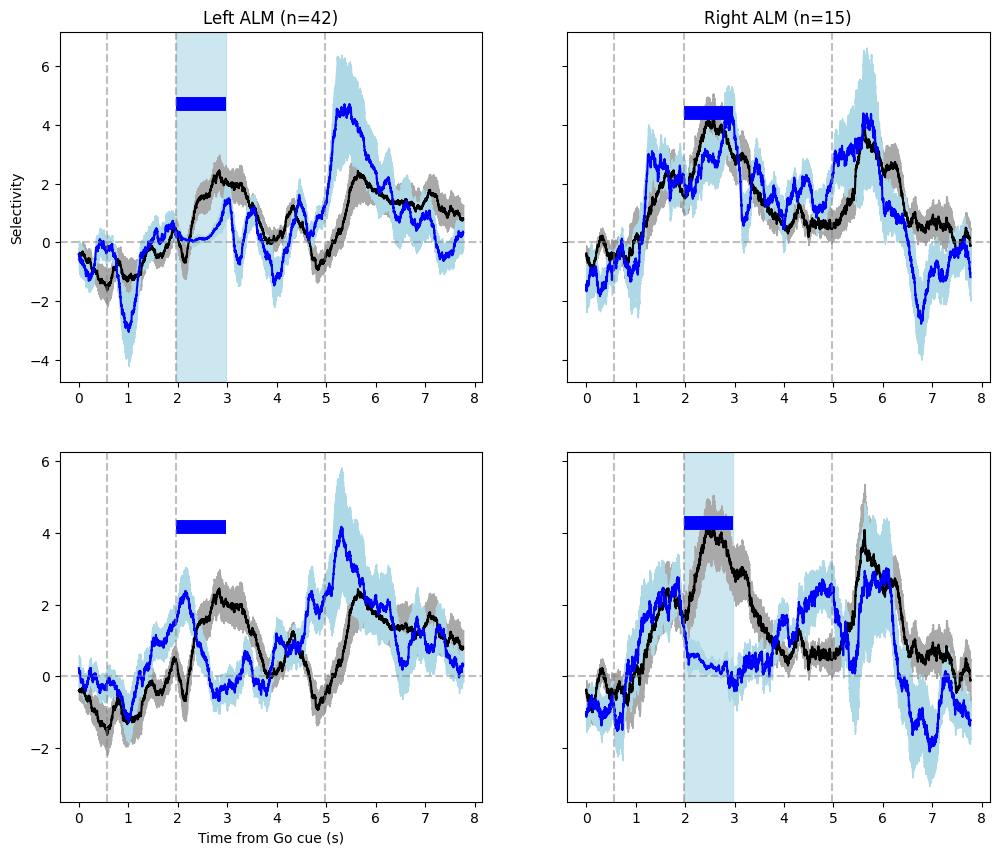

Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 458 --> 375


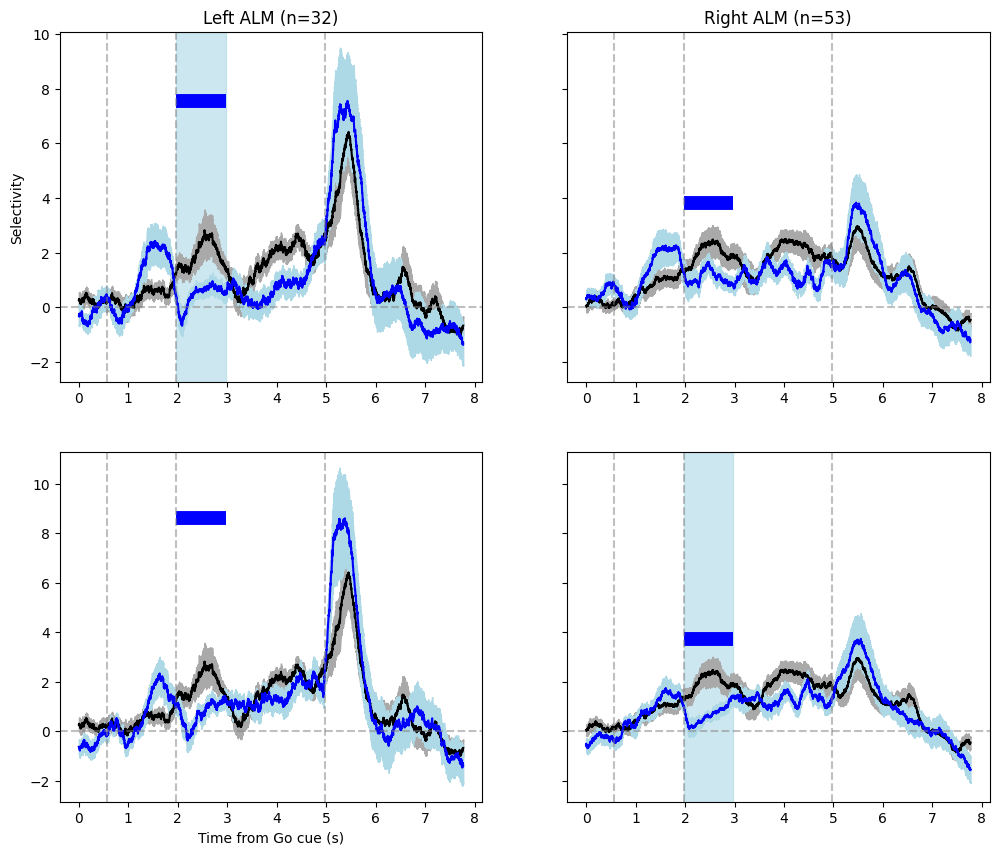

Remove 0 trials from session for bad behavior
13 trials removed for stability reasons
only ppyr neurons: 193 --> 146
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and 17 L trials
There are fewer than 20 trials R/L: 12 R trials and

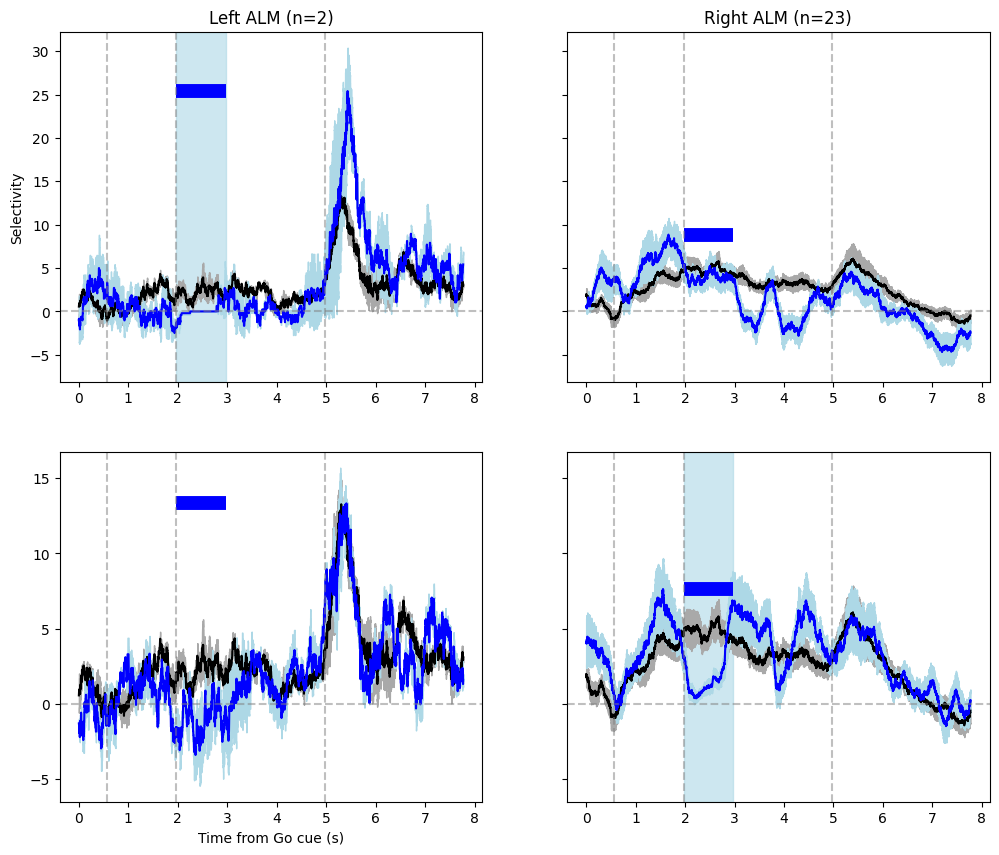

Remove 0 trials from session for bad behavior
18 trials removed for stability reasons
only ppyr neurons: 339 --> 286


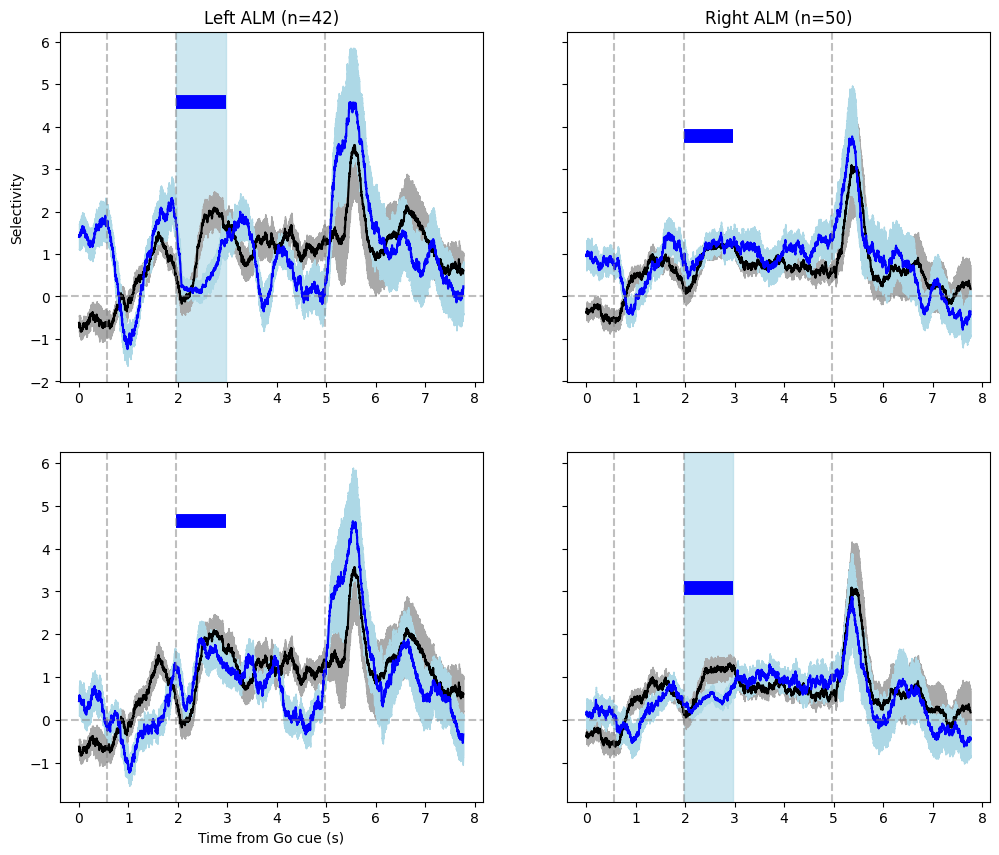

Remove 0 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 222 --> 184
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 17 L trials
There are fewer than 20 trials R/L: 15 R trials and 

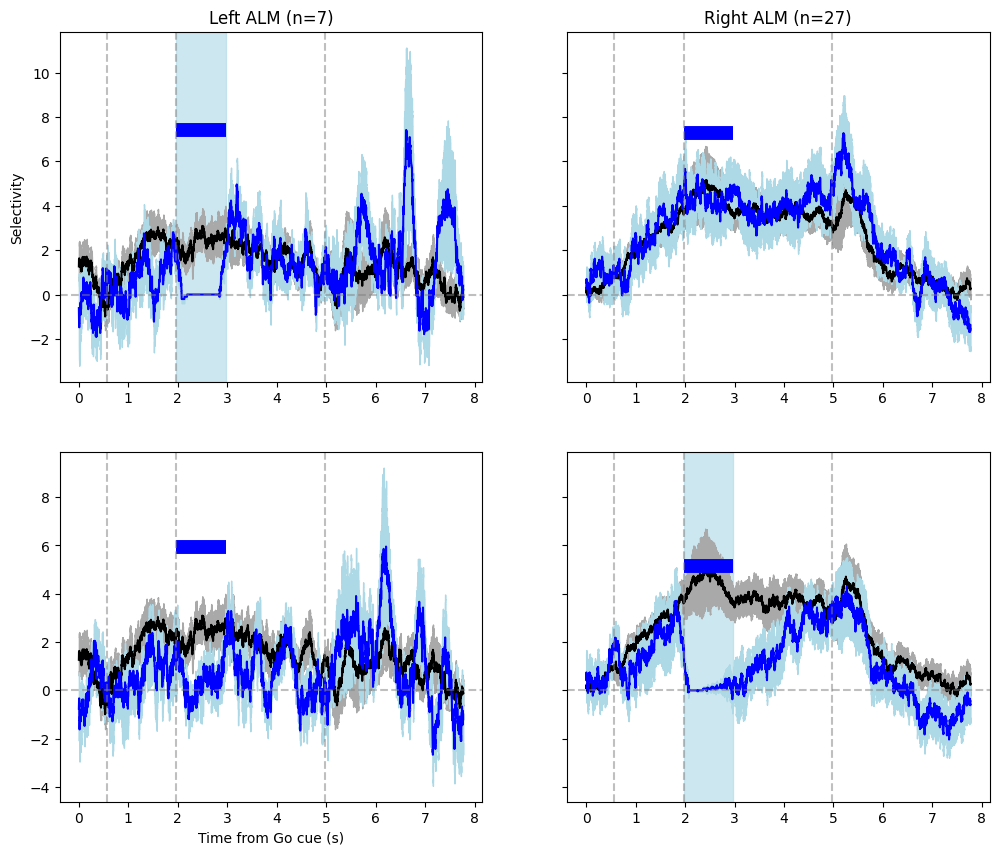

In [10]:
for path in reversed_mouse:
    s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    epoch = (s1.delay, s1.response)
    left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                        p=0.01,
                                                        binsize=200,
                                                        timestep=100,
                                                        bootstrap=False)

    plot_selectivity_recovery(s1, left_info, right_info)

In [3]:
def plot_selectivity_recovery(s1, left_info, right_info):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    # axarr[1,1].set_ylim(bottom=-2)

    plt.show()

def plot_selectivity(s1, left_info, right_info, n_sessions=None):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(1, 2, sharey=True, figsize=(12,5))  # 1 row, 2 columns
    
    # Left ALM subplot (axarr[0])
    axarr[0].plot(time, sel, 'black')
    axarr[0].fill_between(time, sel - err, sel + err, color='darkgray', alpha=0.7)
    title_left = 'Left ALM (n={} sessions)'.format(n_sessions) if n_sessions is not None else 'Left ALM (n={})'.format(len([n for n in s1.selective_neurons if n in s1.L_alm_idx]))
    axarr[0].set_title(title_left)
    axarr[0].set_ylabel('Selectivity')
    axarr[0].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
    axarr[0].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
    axarr[0].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
    axarr[0].axhline(0, color = 'grey', alpha=0.5, ls = '--')

    # Right ALM subplot (axarr[1])
    axarr[1].plot(time, sel_R, 'black')
    axarr[1].fill_between(time, sel_R - err_R, sel_R + err_R, color='darkgray', alpha=0.7)
    title_right = 'Right ALM (n={} sessions)'.format(n_sessions) if n_sessions is not None else 'Right ALM (n={})'.format(len([n for n in s1.selective_neurons if n in s1.R_alm_idx]))
    axarr[1].set_title(title_right)
    axarr[1].set_xlabel('Time from Go cue (s)')
    axarr[1].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
    axarr[1].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
    axarr[1].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
    axarr[1].axhline(0, color = 'grey', alpha=0.5, ls = '--')

